In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv(
    "aquaculture-farmed-fish-production.csv"
)

# Display the first five records
print("First five records:")
display(df.head())

# Display the dataset dimensions
print("\nDataset dimensions:")
print(df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:")
print(df.duplicated().sum())

# Check the year range
print("\nYear range:")
print(df["Year"].min(), "to", df["Year"].max())

# Count entities
print("\nNumber of unique entities:")
print(df["Entity"].nunique())

# Check India's records
india_df = df[df["Entity"] == "India"].copy()

print("\nIndia's dataset:")
display(india_df.head())

print("\nNumber of Indian observations:")
print(len(india_df))

First five records:


,Entity,Code,Year,Aquaculture production (metric tons)
0,Afghanistan,AFG,1969,60.0
1,Afghanistan,AFG,1970,60.0
2,Afghanistan,AFG,1971,60.0
3,Afghanistan,AFG,1972,60.0
4,Afghanistan,AFG,1973,60.0



Dataset dimensions:
(11657, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Entity                                11657 non-null  object 
 1   Code                                  8884 non-null   object 
 2   Year                                  11657 non-null  int64  
 3   Aquaculture production (metric tons)  11657 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 364.4+ KB

Missing values:
Entity                                     0
Code                                    2773
Year                                       0
Aquaculture production (metric tons)       0
dtype: int64

Duplicate records:
0

Year range:
1960 to 2018

Number of unique entities:
242

India's dataset:


,Entity,Code,Year,Aquaculture production (metric tons)
4633,India,IND,1960,44843.0
4634,India,IND,1961,49359.0
4635,India,IND,1962,54368.0
4636,India,IND,1963,59927.0
4637,India,IND,1964,66096.0



Number of Indian observations:
59


**Data cleaning and validation**


In [5]:
# Step 2: Data cleaning and validation

# Create a copy of the original dataset
df_clean = df.copy()

# Remove leading and trailing spaces from entity names
df_clean["Entity"] = df_clean["Entity"].str.strip()

# Check missing values
print("Missing values:")
print(df_clean.isnull().sum())

# Check negative production values
production_col = "Aquaculture production (metric tons)"

negative_values = df_clean[df_clean[production_col] < 0]

print("\nNegative production records:", len(negative_values))

# Check duplicate country-year combinations
duplicate_country_year = df_clean.duplicated(
    subset=["Entity", "Year"]
)

print(
    "\nDuplicate country-year combinations:",
    duplicate_country_year.sum()
)

# Check whether production values are numeric
print("\nProduction data type:")
print(df_clean[production_col].dtype)

# Check the number of observations per entity
records_per_entity = df_clean.groupby("Entity")["Year"].count()

print("\nObservations per entity:")
print(records_per_entity.describe())

# Display the cleaned dataset
display(df_clean.head())

Missing values:
Entity                                     0
Code                                    2773
Year                                       0
Aquaculture production (metric tons)       0
dtype: int64

Negative production records: 0

Duplicate country-year combinations: 0

Production data type:
float64

Observations per entity:
count    242.000000
mean      48.169421
std       14.813089
min        4.000000
25%       35.000000
50%       59.000000
75%       59.000000
max       59.000000
Name: Year, dtype: float64


,Entity,Code,Year,Aquaculture production (metric tons)
0,Afghanistan,AFG,1969,60.0
1,Afghanistan,AFG,1970,60.0
2,Afghanistan,AFG,1971,60.0
3,Afghanistan,AFG,1972,60.0
4,Afghanistan,AFG,1973,60.0


**Analyse India's Production**

In [6]:
# Filter India's records
india_df = df_clean[
    df_clean["Entity"] == "India"
].copy()

# Sort by year
india_df = india_df.sort_values("Year")

# Display the first and last observations
print("First five observations:")
display(india_df.head())

print("Last five observations:")
display(india_df.tail())

# Summary statistics
print("\nSummary statistics for India:")
print(
    india_df[
        ["Year", production_col]
    ].describe()
)

First five observations:


,Entity,Code,Year,Aquaculture production (metric tons)
4633,India,IND,1960,44843.0
4634,India,IND,1961,49359.0
4635,India,IND,1962,54368.0
4636,India,IND,1963,59927.0
4637,India,IND,1964,66096.0


Last five observations:


,Entity,Code,Year,Aquaculture production (metric tons)
4687,India,IND,2014,4893002.0
4688,India,IND,2015,5263002.0
4689,India,IND,2016,5702002.0
4690,India,IND,2017,6184869.0
4691,India,IND,2018,7071302.0



Summary statistics for India:
              Year  Aquaculture production (metric tons)
count    59.000000                          5.900000e+01
mean   1989.000000                          1.672865e+06
std      17.175564                          1.806196e+06
min    1960.000000                          4.484300e+04
25%    1974.500000                          2.030690e+05
50%    1989.000000                          1.004500e+06
75%    2003.500000                          2.560654e+06
max    2018.000000                          7.071302e+06


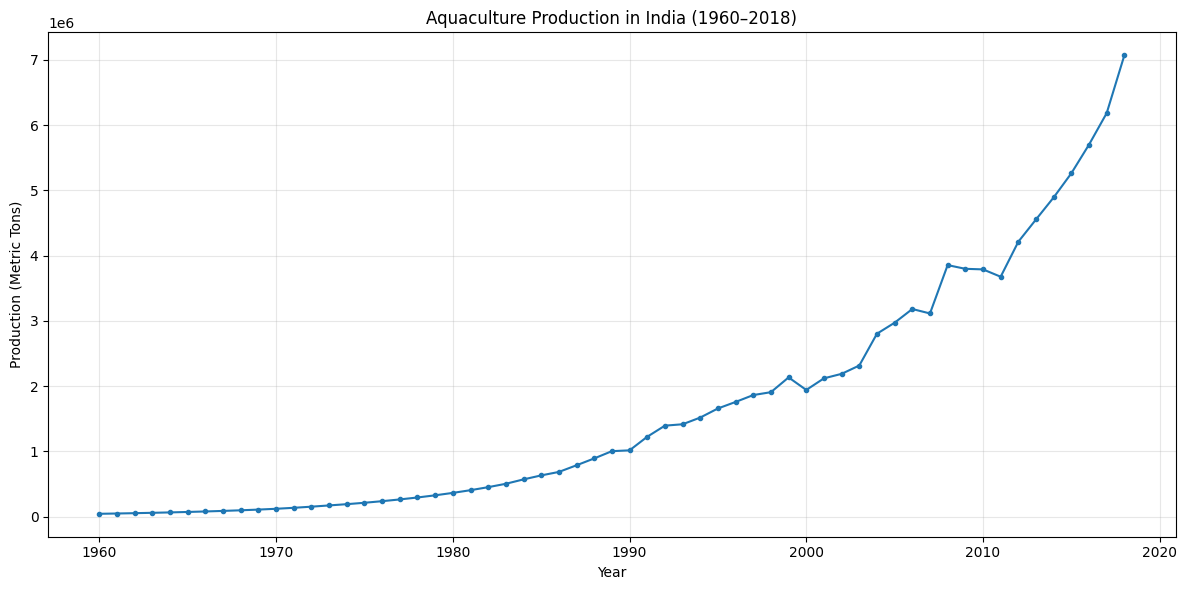

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    india_df["Year"],
    india_df[production_col],
    marker="o",
    markersize=3
)

plt.title("Aquaculture Production in India (1960–2018)")
plt.xlabel("Year")
plt.ylabel("Production (Metric Tons)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Compare India with Other Countries**

In [8]:
# Latest year available in the dataset
latest_year = df_clean["Year"].max()

# Production by entity in the latest year
latest_production = df_clean[
    df_clean["Year"] == latest_year
].copy()

# Sort entities by production
top_10_countries = latest_production.sort_values(
    by=production_col,
    ascending=False
).head(10)

print(f"Top 10 entities by production in {latest_year}:")

display(
    top_10_countries[
        ["Entity", "Year", production_col]
    ]
)

Top 10 entities by production in 2018:


,Entity,Year,Aquaculture production (metric tons)
4396,IDA & IBRD total,2018,1.064513e+08
6121,Low & middle income,2018,1.057320e+08
6911,Middle income,2018,1.049401e+08
4337,IBRD only,2018,1.015457e+08
2414,East Asia & Pacific,2018,9.459921e+07
2532,East Asia & Pacific (excluding high income),2018,9.078835e+07
2473,East Asia & Pacific (IDA & IBRD),2018,9.015929e+07
5553,Late-demographic dividend,2018,7.469476e+07
11149,Upper middle income,2018,6.980319e+07
1761,China,2018,6.613506e+07


**Calculate India's Growth Rate**

In [9]:
# Step 5: Growth analysis for India

india_df = india_df.sort_values("Year").copy()

# Year-on-year change in production
india_df["Production Change"] = (
    india_df[production_col].diff()
)

# Year-on-year percentage growth
india_df["YoY Growth (%)"] = (
    india_df[production_col].pct_change() * 100
)

# First and last observations
first_year = india_df.iloc[0]["Year"]
last_year = india_df.iloc[-1]["Year"]

first_production = india_df.iloc[0][production_col]
last_production = india_df.iloc[-1][production_col]

# Total absolute change
absolute_change = last_production - first_production

# Total percentage change
total_percentage_change = (
    (last_production / first_production) - 1
) * 100

# Compound Annual Growth Rate
number_of_years = last_year - first_year

cagr = (
    (last_production / first_production)
    ** (1 / number_of_years) - 1
) * 100

print(f"Starting year: {int(first_year)}")
print(f"Ending year: {int(last_year)}")

print(f"\nStarting production: {first_production:,.0f} metric tons")
print(f"Ending production: {last_production:,.0f} metric tons")

print(f"\nAbsolute increase: {absolute_change:,.0f} metric tons")
print(f"Total percentage increase: {total_percentage_change:.2f}%")
print(f"CAGR: {cagr:.2f}% per year")

print("\nYears with the highest annual growth:")
display(
    india_df.nlargest(5, "YoY Growth (%)")[
        ["Year", production_col, "YoY Growth (%)"]
    ]
)

print("\nYears with the largest annual declines:")
display(
    india_df.nsmallest(5, "YoY Growth (%)")[
        ["Year", production_col, "YoY Growth (%)"]
    ]
)

Starting year: 1960
Ending year: 2018

Starting production: 44,843 metric tons
Ending production: 7,071,302 metric tons

Absolute increase: 7,026,459 metric tons
Total percentage increase: 15669.02%
CAGR: 9.12% per year

Years with the highest annual growth:


,Year,Aquaculture production (metric tons),YoY Growth (%)
4681,2008,3855763.0,23.789972
4677,2004,2804362.0,21.036951
4664,1991,1225261.0,20.461865
4660,1987,788310.0,14.870457
4685,2012,4213980.0,14.585554



Years with the largest annual declines:


,Year,Aquaculture production (metric tons),YoY Growth (%)
4673,2000,1942531.0,-9.007014
4684,2011,3677584.0,-2.966659
4680,2007,3114762.0,-2.138200
4682,2009,3798842.0,-1.476258
4683,2010,3790021.0,-0.232202


**Identify the Top 10 Countries in 2018**

In [10]:
# Step 6: Country-level comparison

latest_year = df_clean["Year"].max()

latest_data = df_clean[
    df_clean["Year"] == latest_year
].copy()

# Retain entities with a non-missing code
country_data = latest_data[
    latest_data["Code"].notna()
].copy()

# Rank by production
top_10_countries = country_data.sort_values(
    production_col,
    ascending=False
).head(10)

print(f"Top 10 coded entities by production in {latest_year}:")

display(
    top_10_countries[
        ["Entity", "Code", "Year", production_col]
    ].reset_index(drop=True)
)

Top 10 coded entities by production in 2018:


,Entity,Code,Year,Aquaculture production (metric tons)
0,China,CHN,2018,6.613506e+07
1,Indonesia,IDN,2018,1.477210e+07
2,India,IND,2018,7.071302e+06
3,Vietnam,VNM,2018,4.153322e+06
4,Bangladesh,BGD,2018,2.405416e+06
5,Philippines,PHL,2018,2.304361e+06
6,South Korea,KOR,2018,2.278850e+06
7,Egypt,EGY,2018,1.561457e+06
8,Norway,NOR,2018,1.355117e+06
9,Chile,CHL,2018,1.287232e+06


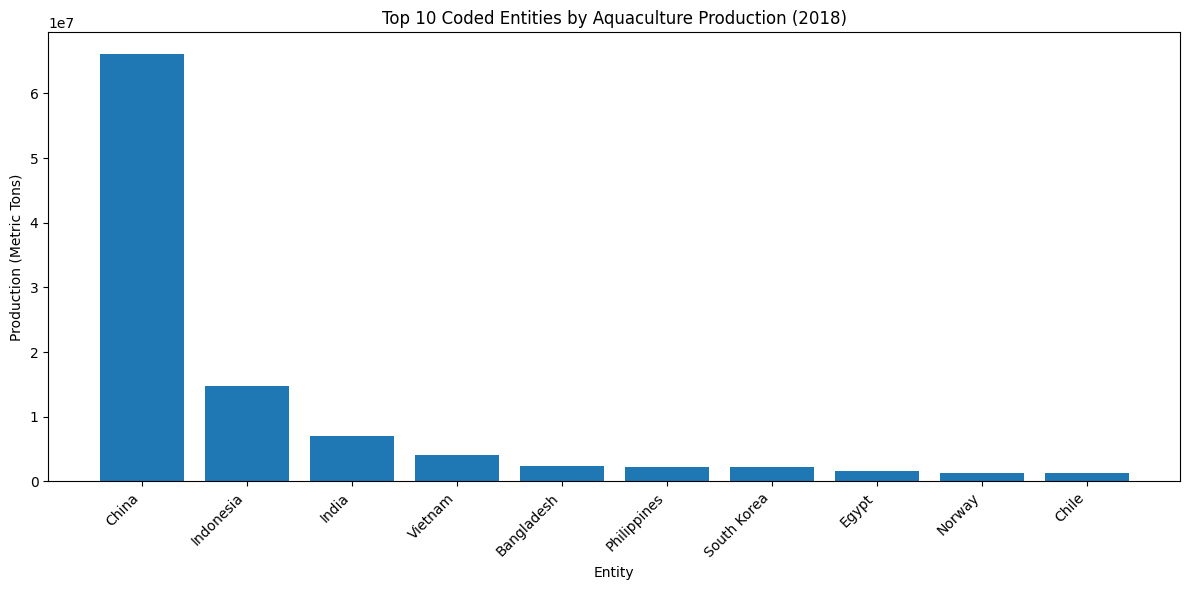

In [11]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_countries["Entity"],
    top_10_countries[production_col]
)

plt.title(f"Top 10 Coded Entities by Aquaculture Production ({latest_year})")
plt.xlabel("Entity")
plt.ylabel("Production (Metric Tons)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

**Analyse Production Across All Entities**

In [12]:
# Compare the first and last years
start_data = df_clean[
    df_clean["Year"] == 1960
][["Entity", "Code", production_col]].copy()

end_data = df_clean[
    df_clean["Year"] == 2018
][["Entity", "Code", production_col]].copy()

# Keep coded entities for comparison
start_data = start_data[
    start_data["Code"].notna()
]

end_data = end_data[
    end_data["Code"].notna()
]

print("Number of coded entities in 1960:", len(start_data))
print("Number of coded entities in 2018:", len(end_data))

print("\nTop 10 coded entities in 1960:")
display(
    start_data.nlargest(10, production_col)[
        ["Entity", production_col]
    ].reset_index(drop=True)
)

print("\nTop 10 coded entities in 2018:")
display(
    end_data.nlargest(10, production_col)[
        ["Entity", production_col]
    ].reset_index(drop=True)
)

Number of coded entities in 1960: 87
Number of coded entities in 2018: 192

Top 10 coded entities in 1960:


,Entity,Aquaculture production (metric tons)
0,World,2029179.0
1,China,958506.0
2,Japan,308044.0
3,France,111100.0
4,United States,104421.0
5,Indonesia,80639.0
6,Netherlands,77600.0
7,Philippines,60769.0
8,Bangladesh,49237.0
9,India,44843.0



Top 10 coded entities in 2018:


,Entity,Aquaculture production (metric tons)
0,China,6.613506e+07
1,Indonesia,1.477210e+07
2,India,7.071302e+06
3,Vietnam,4.153322e+06
4,Bangladesh,2.405416e+06
5,Philippines,2.304361e+06
6,South Korea,2.278850e+06
7,Egypt,1.561457e+06
8,Norway,1.355117e+06
9,Chile,1.287232e+06


**Preparing India's Data for Machine Learning**

*Create the training and testing datasets*

In [13]:
# Step 8: Prepare data for forecasting

from sklearn.model_selection import train_test_split

# Sort India's data chronologically
india_ml = india_df[
    ["Year", production_col]
].copy()

india_ml = india_ml.sort_values("Year").reset_index(drop=True)

# Define input and target
X = india_ml[["Year"]]
y = india_ml[production_col]

# Chronological split: first 80% for training, last 20% for testing
split_index = int(len(india_ml) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training period:", X_train["Year"].min(), "-", X_train["Year"].max())
print("Testing period:", X_test["Year"].min(), "-", X_test["Year"].max())

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

Training period: 1960 - 2006
Testing period: 2007 - 2018

Training observations: 47
Testing observations: 12


*Establish a baseline forecast*

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict the last training year's production for every test year
baseline_predictions = np.full(
    len(y_test),
    y_train.iloc[-1]
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 1505220.33
Baseline RMSE: 1873678.42


**Training First Machine Learning Model**

In [15]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict production for the test years
linear_predictions = linear_model.predict(X_test)

# Evaluate performance
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("Coefficient:", round(linear_model.coef_[0], 2))
print("Intercept:", round(linear_model.intercept_, 2))

Linear Regression Results
-------------------------
MAE: 1946191.15
RMSE: 2157013.92
Coefficient: 61849.97
Intercept: -121742560.35


*Compare actual and predicted production*

In [16]:
# Compare actual and predicted values
comparison = pd.DataFrame({
    "Year": X_test["Year"].values,
    "Actual Production": y_test.values,
    "Predicted Production": linear_predictions
})

display(comparison.round(2))

,Year,Actual Production,Predicted Production
0,2007,3114762.0,2390328.85
1,2008,3855763.0,2452178.82
2,2009,3798842.0,2514028.79
3,2010,3790021.0,2575878.76
4,2011,3677584.0,2637728.73
5,2012,4213980.0,2699578.70
6,2013,4555209.0,2761428.67
7,2014,4893002.0,2823278.64
8,2015,5263002.0,2885128.60
9,2016,5702002.0,2946978.57


*Visualise the predictions*

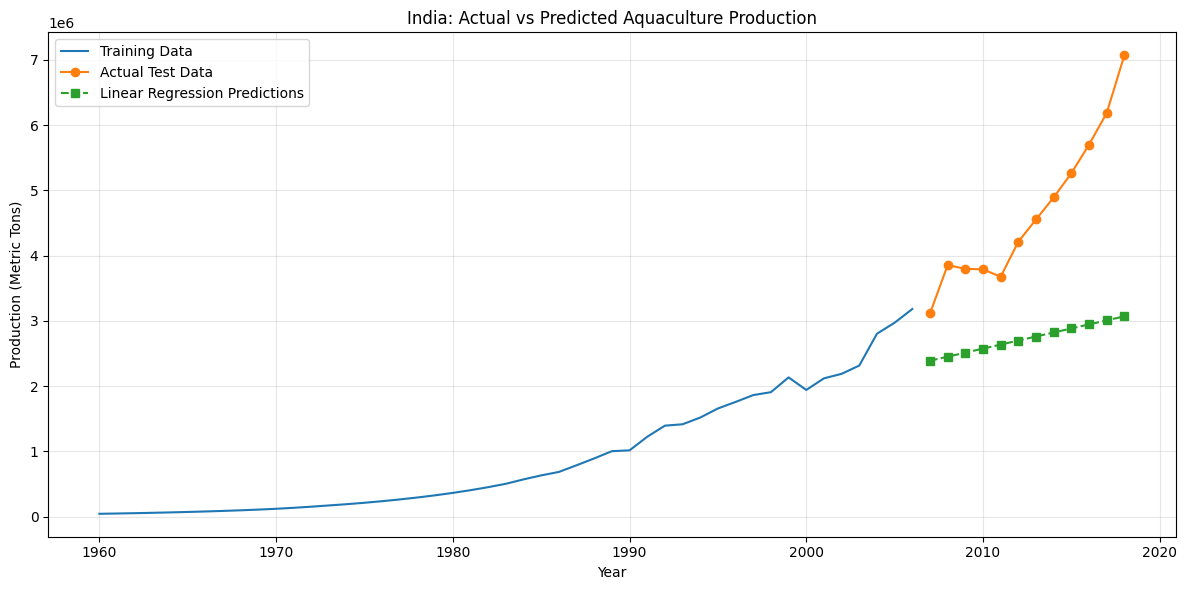

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    X_train["Year"],
    y_train,
    label="Training Data"
)

plt.plot(
    X_test["Year"],
    y_test,
    marker="o",
    label="Actual Test Data"
)

plt.plot(
    X_test["Year"],
    linear_predictions,
    linestyle="--",
    marker="s",
    label="Linear Regression Predictions"
)

plt.title("India: Actual vs Predicted Aquaculture Production")
plt.xlabel("Year")
plt.ylabel("Production (Metric Tons)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Test Models That Can Capture Changing Growth**

*Polynomial Regression*

In [18]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Polynomial Regression with degree 2
polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Train
polynomial_model.fit(X_train, y_train)

# Predict
polynomial_predictions = polynomial_model.predict(X_test)

# Evaluate
polynomial_mae = mean_absolute_error(
    y_test, polynomial_predictions
)

polynomial_rmse = np.sqrt(
    mean_squared_error(y_test, polynomial_predictions)
)

print("Polynomial Regression (Degree 2)")
print("MAE:", round(polynomial_mae, 2))
print("RMSE:", round(polynomial_rmse, 2))

Polynomial Regression (Degree 2)
MAE: 649321.06
RMSE: 859694.61


*Exponential Regression*

In [19]:
# Exponential trend model
exponential_model = LinearRegression()

# Use years relative to the first training year
X_train_relative = (
    X_train["Year"].to_numpy() - X_train["Year"].min()
).reshape(-1, 1)

X_test_relative = (
    X_test["Year"].to_numpy() - X_train["Year"].min()
).reshape(-1, 1)

# Fit a linear model to log production
exponential_model.fit(
    X_train_relative,
    np.log(y_train)
)

# Predict log production and convert back to production
exponential_predictions = np.exp(
    exponential_model.predict(X_test_relative)
)

# Evaluate
exponential_mae = mean_absolute_error(
    y_test, exponential_predictions
)

exponential_rmse = np.sqrt(
    mean_squared_error(y_test, exponential_predictions)
)

print("Exponential Regression")
print("MAE:", round(exponential_mae, 2))
print("RMSE:", round(exponential_rmse, 2))

Exponential Regression
MAE: 3564307.78
RMSE: 3914237.07


*Holt's Linear Trend*

In [20]:
from statsmodels.tsa.holtwinters import Holt

# Fit Holt's trend model to the training observations
holt_model = Holt(
    y_train.to_numpy(),
    initialization_method="estimated"
).fit(optimized=True)

# Forecast the test period
holt_predictions = holt_model.forecast(len(y_test))

# Evaluate
holt_mae = mean_absolute_error(
    y_test, holt_predictions
)

holt_rmse = np.sqrt(
    mean_squared_error(y_test, holt_predictions)
)

print("Holt's Linear Trend")
print("MAE:", round(holt_mae, 2))
print("RMSE:", round(holt_rmse, 2))

Holt's Linear Trend
MAE: 365126.65
RMSE: 515103.11


**Compare All Models**

In [21]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Polynomial Regression",
        "Exponential Regression",
        "Holt's Linear Trend"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        polynomial_mae,
        exponential_mae,
        holt_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        polynomial_rmse,
        exponential_rmse,
        holt_rmse
    ]
})

results = results.sort_values("MAE").reset_index(drop=True)

display(results.round(2))

,Model,MAE,RMSE
0,Holt's Linear Trend,365126.65,515103.11
1,Polynomial Regression,649321.06,859694.61
2,Baseline,1505220.33,1873678.42
3,Linear Regression,1946191.15,2157013.92
4,Exponential Regression,3564307.78,3914237.07


**Plot the Model Predictions**

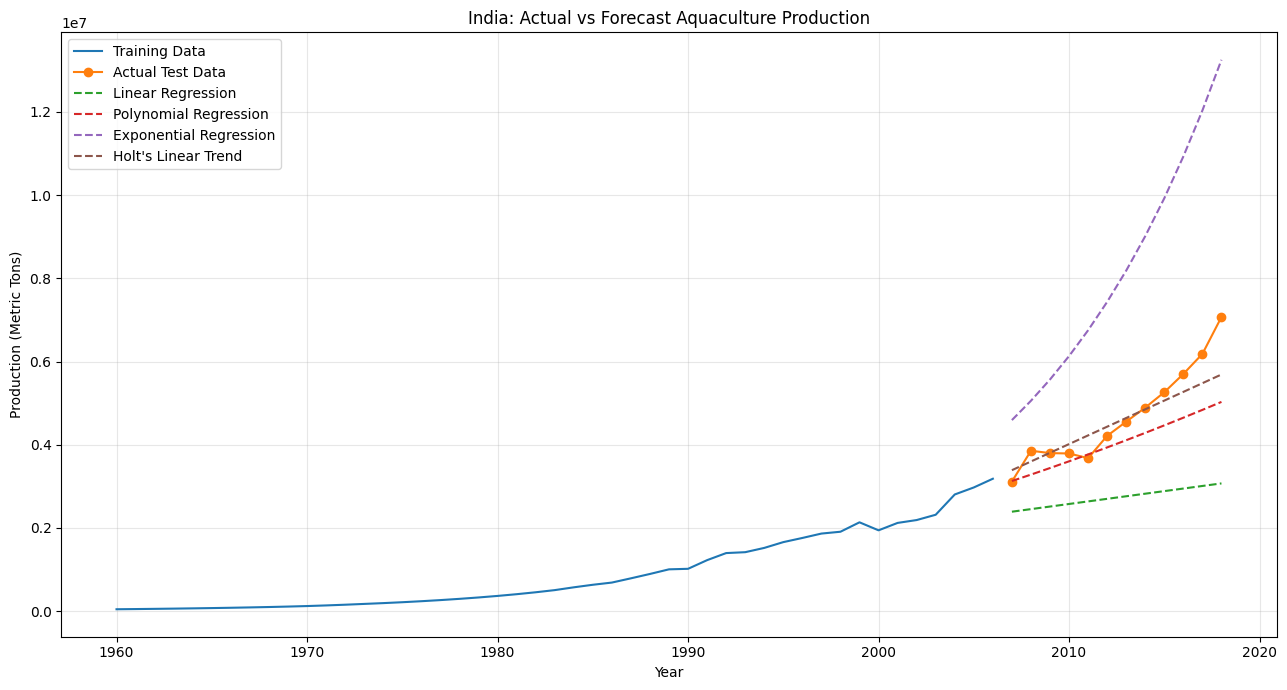

In [22]:
plt.figure(figsize=(13, 7))

plt.plot(
    X_train["Year"],
    y_train,
    label="Training Data"
)

plt.plot(
    X_test["Year"],
    y_test,
    marker="o",
    label="Actual Test Data"
)

plt.plot(
    X_test["Year"],
    linear_predictions,
    linestyle="--",
    label="Linear Regression"
)

plt.plot(
    X_test["Year"],
    polynomial_predictions,
    linestyle="--",
    label="Polynomial Regression"
)

plt.plot(
    X_test["Year"],
    exponential_predictions,
    linestyle="--",
    label="Exponential Regression"
)

plt.plot(
    X_test["Year"],
    holt_predictions,
    linestyle="--",
    label="Holt's Linear Trend"
)

plt.title("India: Actual vs Forecast Aquaculture Production")
plt.xlabel("Year")
plt.ylabel("Production (Metric Tons)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Validating the Models**

In [23]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import Holt

# Prepare India's complete time series
series = (
    india_df.sort_values("Year")
    .set_index("Year")[production_col]
)

# Each origin predicts the following five years
forecast_origins = [1989, 1994, 1999, 2004, 2009, 2013]

validation_results = []

for origin in forecast_origins:

    train = series.loc[:origin]
    test = series.loc[origin + 1:origin + 5]

    if len(test) != 5:
        continue

    # Baseline: repeat the last observed production
    baseline_pred = np.full(len(test), train.iloc[-1])

    # Years relative to the first training year
    X_train = (
        train.index.to_numpy() - train.index.min()
    ).reshape(-1, 1)

    X_test = (
        test.index.to_numpy() - train.index.min()
    ).reshape(-1, 1)

    # Linear Regression
    linear = LinearRegression()
    linear.fit(X_train, train.to_numpy())
    linear_pred = linear.predict(X_test)

    # Polynomial Regression, degree 2
    polynomial = make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    )
    polynomial.fit(X_train, train.to_numpy())
    polynomial_pred = polynomial.predict(X_test)

    # Holt's Linear Trend
    holt = Holt(
        train.to_numpy(),
        initialization_method="estimated"
    ).fit(optimized=True)

    holt_pred = holt.forecast(len(test))

    predictions = {
        "Baseline": baseline_pred,
        "Linear Regression": linear_pred,
        "Polynomial Regression": polynomial_pred,
        "Holt's Linear Trend": holt_pred
    }

    for model_name, pred in predictions.items():

        validation_results.append({
            "Origin Year": origin,
            "Test Period": f"{origin + 1}-{origin + 5}",
            "Model": model_name,
            "MAE": mean_absolute_error(test, pred),
            "RMSE": np.sqrt(mean_squared_error(test, pred))
        })

validation_df = pd.DataFrame(validation_results)

# Show results for every evaluation period
display(validation_df.round(2))

# Summarise average errors across evaluation periods
summary = (
    validation_df.groupby("Model")[["MAE", "RMSE"]]
    .mean()
    .sort_values("MAE")
)

print("Average error across evaluation periods:")
display(summary.round(2))

,Origin Year,Test Period,Model,MAE,RMSE
0,1989,1990-1994,Baseline,310314.20,356902.40
1,1989,1990-1994,Linear Regression,511534.60,529857.64
2,1989,1990-1994,Polynomial Regression,165422.23,182009.86
3,1989,1990-1994,Holt's Linear Trend,46009.80,56003.26
4,1994,1995-1999,Baseline,345505.40,380885.25
5,1994,1995-1999,Linear Regression,626271.06,635322.42
6,1994,1995-1999,Polynomial Regression,65377.97,72584.57
7,1994,1995-1999,Holt's Linear Trend,27881.93,38490.16
8,1999,2000-2004,Baseline,222555.00,322993.91
9,1999,2000-2004,Linear Regression,526047.65,572820.13


Average error across evaluation periods:


,MAE,RMSE
Model,,
Holt's Linear Trend,295519.45,338869.39
Polynomial Regression,319755.56,362818.48
Baseline,534308.30,641884.14
Linear Regression,1047887.71,1090791.88


**Forecast India's Production for 2019–2028**

In [24]:
# Fit Holt's method on all available Indian observations
final_model = Holt(
    series.to_numpy(),
    initialization_method="estimated"
).fit(optimized=True)

# Forecast the next 10 years
future_years = np.arange(
    int(series.index.max()) + 1,
    int(series.index.max()) + 11
)

future_predictions = final_model.forecast(10)

# Create a forecast table
forecast_df = pd.DataFrame({
    "Year": future_years,
    "Predicted Production (Metric Tons)": future_predictions
})

forecast_df["Predicted Production (Metric Tons)"] = (
    forecast_df["Predicted Production (Metric Tons)"]
    .clip(lower=0)
)

display(forecast_df.round(0))

,Year,Predicted Production (Metric Tons)
0,2019,7516935.0
1,2020,8097774.0
2,2021,8678612.0
3,2022,9259450.0
4,2023,9840289.0
5,2024,10421127.0
6,2025,11001966.0
7,2026,11582804.0
8,2027,12163642.0
9,2028,12744481.0


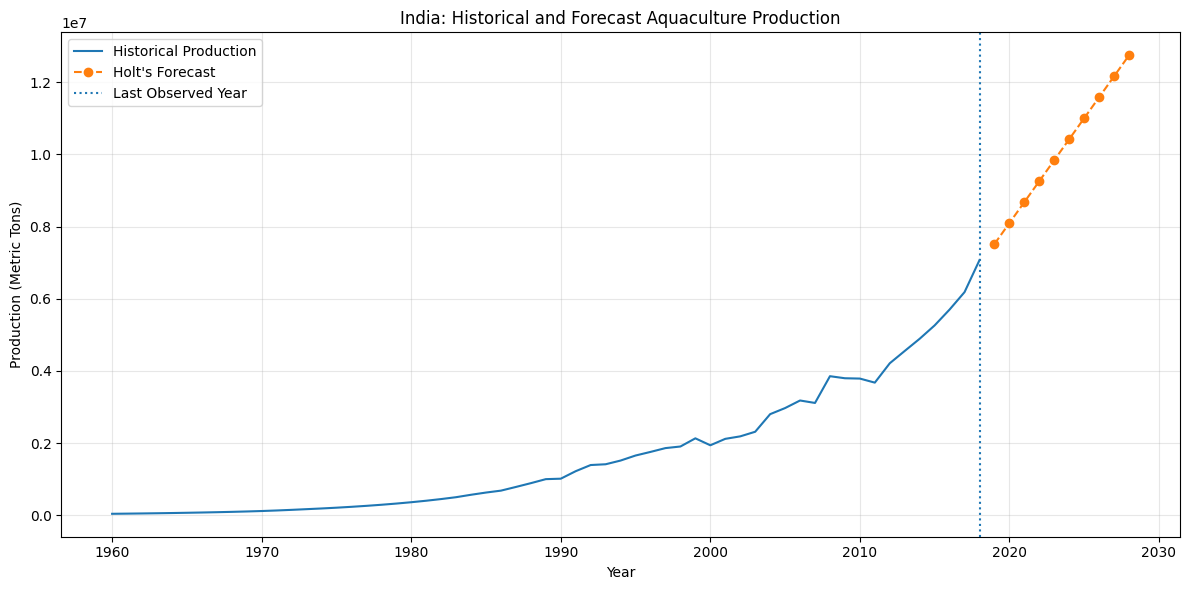

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    series.index,
    series.values,
    label="Historical Production"
)

plt.plot(
    future_years,
    future_predictions,
    marker="o",
    linestyle="--",
    label="Holt's Forecast"
)

plt.axvline(
    x=2018,
    linestyle=":",
    label="Last Observed Year"
)

plt.title("India: Historical and Forecast Aquaculture Production")
plt.xlabel("Year")
plt.ylabel("Production (Metric Tons)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Export DataFrames to CSV files first
df_clean.to_csv("aquaculture_cleaned.csv", index=False)
forecast_df.to_csv("india_aquaculture_forecast.csv", index=False)
validation_df.to_csv("model_validation_results.csv", index=False)

# Download the generated CSV files
from google.colab import files

files.download("aquaculture_cleaned.csv")
files.download("india_aquaculture_forecast.csv")
files.download("model_validation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>